# 01 · Pulizia dei dati e controlli di qualità

**Progetto:** *Qual'e' il numero minimo di doamnde che ci fa ottenere un risultato attendibile?*

Ogni domanda in più in un test del aumenta il rischio che l utente abbandoni il questionario; ogni domanda in meno rende il profilo meno preciso. Questo progetto misura, su dati reali, **quanto vale ogni domanda** nel capire i gusti di una persona, e dove si trova la lunghezza oltre la quale il test non migliora più considerevolmente.

**Dati.** *Candy Hierarchy*, il sondaggio di David Ng e Ben Cohen (University of British Columbia, pubblicato su BoingBoing). Migliaia di persone indicano, per ogni dolce di Halloween, se dà loro **gioia** o **delusione**.

| | 2015 | 2017 |
|---|---|---|
| Ruolo nel progetto | **scoperta**: costruisco profili e test | **replica**: verifico su persone nuove |
| Scala | gioia / delusione | gioia / *indifferenza* / delusione |

Utilizzero anche il dataset **FiveThirtyEight Candy Power Ranking**, con le caratteristiche dei dolci (cioccolato, frutta, caramello…), che uso per controllare la codifica sensoriale.

| Notebook | Contenuto |
|---|---|
| **01 · Pulizia** | selezione dei prodotti, qualità dei rispondenti, codifica |
| 02 · Profili di gusto | i 5 Caratteri sensoriali, stabilità, validazione |
| 03 · Valore delle domande | curva domande-accuratezza, ordine ottimale, test adattivo, lunghezza ottimale |
| 04 · Replica 2017 | il test progettato sul 2015 funziona su nuove persone? |

In [14]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from catalogo import CATALOGO, ATTRIBUTI, ESCLUSI, chiave, trova_colonna
from stile_grafici import applica_stile, salva, BLU, ARANCIO, GRIGIO, TESTO_2

applica_stile()
pd.set_option("display.width", 140)

raw15 = pd.read_csv("../data/raw/candyhierarchy2015.csv")
raw17 = pd.read_csv("../data/raw/candyhierarchy2017.csv", encoding="latin-1")
attr538 = pd.read_csv("../data/raw/fivethirtyeight_candy_attributes.csv", encoding="latin-1")
print(f"2015: {raw15.shape[0]:,} righe × {raw15.shape[1]} colonne")
print(f"2017: {raw17.shape[0]:,} righe × {raw17.shape[1]} colonne")
print(f"FiveThirtyEight: {len(attr538)} dolci con attributi")


2015: 5,658 righe × 124 colonne
2017: 2,460 righe × 120 colonne
FiveThirtyEight: 85 dolci con attributi


## 1. Che cosa contiene il questionario

Le colonne del 2015 sono di tre tipi: le **voci da valutare** (nel formato ` [Nome]`), alcune domande **non legate al gusto** (età, se si va a fare dolcetto o scherzetto, il colore del famoso "vestito"…) e molti campi **a testo libero o scherzosi**.

In [15]:
voci15 = {c.strip()[1:-1]: c for c in raw15.columns if c.startswith(" [")}
voci17 = {c[5:]: c for c in raw17.columns if c.startswith("Q6 |")}
print(f"Voci da valutare: {len(voci15)} nel 2015, {len(voci17)} nel 2017\n")
print("Esempi di voci 2015:", list(voci15)[:8], "...\n")
vuote = [c for c in raw15.columns if raw15[c].isna().all()]
print(f"Colonne 2015 completamente vuote: {len(vuote)}")

Voci da valutare: 95 nel 2015, 103 nel 2017

Esempi di voci 2015: ['Butterfinger', '100 Grand Bar', 'Anonymous brown globs that come in black and orange wrappers', 'Any full-sized candy bar', 'Black Jacks', 'Bonkers', 'Bottle Caps', 'Box’o’ Raisins'] ...

Colonne 2015 completamente vuote: 9


## 2. Il catalogo: quali voci sono davvero "prodotti"

Non tutte le voci sono dolci. Il sondaggio è volutamente ironico e include *contanti*, *Vicodin*, *matite*, *abbracci*, dolci inventati e giudizi travestiti da prodotti (*Jolly Rancher, gusto cattivo*). Tenere queste voci renderebbe i profili meno interpretabili: un "profilo" basato sul gradimento delle matite non serve a nessun brand.

Applico quattro regole di esclusione e tengo solo i **dolci presenti in entrambi gli anni**, così che la replica sul 2017 confronti esattamente lo stesso catalogo. I nomi vanno normalizzati, perché gli apostrofi cambiano da un anno all'altro (`Reese’s` contro `ReeseÕs`, un errore di codifica nel file 2017).

In [16]:
print("Esclusioni:")
for motivo, voci in ESCLUSI.items():
    print(f"· {motivo}: {len(voci)} voci, es. {', '.join(voci[:4])}")

# Mappo ogni dolce del catalogo alla sua colonna nei due anni
col15 = {nome: voci15[trova_colonna(list(voci15), k15)] for nome, k15, k17, _, _ in CATALOGO}
col17 = {nome: voci17[trova_colonna(list(voci17), k17)] for nome, k15, k17, _, _ in CATALOGO}

esclusi = [k for v in ESCLUSI.values() for k in v]
usati15 = {c.strip()[1:-1] for c in col15.values()}
usati17 = {c[5:] for c in col17.values()}
solo15 = [v for v in voci15 if v not in usati15 and not any(chiave(v).startswith(e) for e in esclusi)]
solo17 = [v for v in voci17 if v not in usati17 and not any(chiave(v).startswith(e) for e in esclusi)]
print(f"\nDolci presenti in un solo anno (esclusi per confrontabilità): {len(solo15)} solo nel 2015, {len(solo17)} solo nel 2017")
print(f"\n→ Catalogo finale: {len(CATALOGO)} dolci comuni ai due anni")

Esclusioni:
· non è un dolce: 11 voci, es. cash, dental paraphenalia, generic brand acetaminophen, glow sticks
· cibo non dolce o non da Halloween: 7 voci, es. healthy fruit, kale smoothie, minibags of chips, spotted dick
· dolce inventato o fuori commercio: 4 voci, es. joyjoy, sweetums, senior mints, reggie jackson bar
· categoria generica o giudizio, non un prodotto: 6 voci, es. any fullsized candy bar, candy that is clearly just, vials of pure high fructose, jolly rancher bad flavor

Dolci presenti in un solo anno (esclusi per confrontabilità): 10 solo nel 2015, 21 solo nel 2017

→ Catalogo finale: 57 dolci comuni ai due anni


### Gli attributi sensoriali di ogni dolce

Per descrivere i gusti in termini **sensoriali** ho codificato ogni dolce con sei attributi: cioccolato, frutta/acidulo, menta, arachidi o frutta secca, caramello, liquirizia.

Controlla la codifica che ho fatto contro FiveThirtyEight, che ha codificato in modo indipendente 4 degli stessi attributi per una parte dei dolci.

In [17]:
catalogo = pd.DataFrame(CATALOGO, columns=["dolce", "k15", "k17", "nome_538", "attributi"]).drop(columns=["k15", "k17"])
for a in ATTRIBUTI:
    catalogo[a] = catalogo["attributi"].str.split().apply(lambda lst: int(a in lst))

confronto = catalogo.dropna(subset=["nome_538"]).merge(attr538, left_on="nome_538", right_on="competitorname")
coppie = {"cioccolato": "chocolate", "frutta": "fruity", "caramello": "caramel", "arachidi": "peanutyalmondy"}
accordo = pd.DataFrame({
    "attributo": list(coppie),
    "dolci confrontati": len(confronto),
    "concordanza": [(confronto[a] == confronto[b]).mean() for a, b in coppie.items()],
})
print(accordo.to_string(index=False))
disaccordi = [{"dolce": r["dolce"], "attributo": a, "mia codifica": r[a], "FiveThirtyEight": r[b]}
              for a, b in coppie.items() for _, r in confronto[confronto[a] != confronto[b]].iterrows()]
pd.DataFrame(disaccordi)

 attributo  dolci confrontati  concordanza
cioccolato                 31     1.000000
    frutta                 31     0.935484
 caramello                 31     1.000000
  arachidi                 31     1.000000


,dolce,attributo,mia codifica,FiveThirtyEight
0,Chiclets,frutta,0,1
1,Pixy Stix,frutta,1,0


Su 31 dolci in comune, cioccolato, caramello e arachidi coincidono al 100%. I soli due disaccordi riguardano la frutta e sono **casi di definizione**, non errori:

- **Chiclets.** FiveThirtyEight li segna come fruttati, ma la versione classica è alla menta e quella alla frutta è una variante. Li lascio senza attributo frutta.
- **Pixy Stix.** FiveThirtyEight li segna come *non* fruttati, ma sono polveri zuccherate al gusto di frutta. Tengo frutta.

Uso quindi la mia codifica, che copre tutti i 57 dolci, mentre FiveThirtyEight ne copre circa la metà.

## 3. Qualità dei dati (2015)

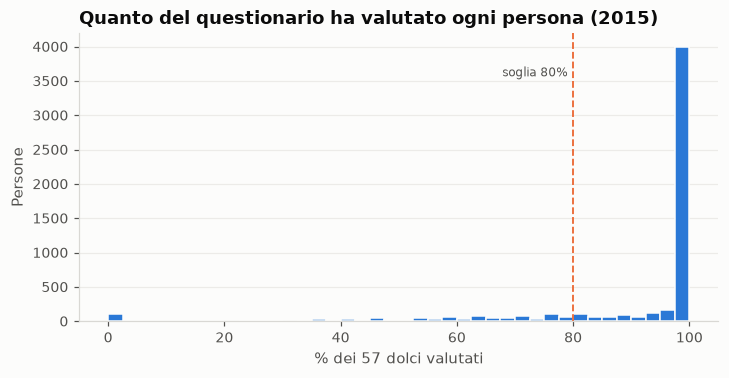

Righe senza nessuna valutazione: 98


In [18]:
# Matrice persone × dolci: 1 = gioia, 0 = delusione, NaN = non risposto
def matrice(raw, colonne, scala):
    return pd.DataFrame({n: raw[c].map(scala) for n, c in colonne.items()})

SCALA15 = {"JOY": 1.0, "DESPAIR": 0.0}
m15 = matrice(raw15, col15, SCALA15)
risposte = m15.notna().mean(axis=1)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(risposte * 100, bins=np.arange(0, 102.5, 2.5), color=BLU, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(80, color=ARANCIO, linestyle="--", linewidth=1.2)
ax.text(79, ax.get_ylim()[1] * 0.85, "soglia 80%", ha="right", fontsize=8, color=TESTO_2)
ax.set_xlabel("% dei 57 dolci valutati"); ax.set_ylabel("Persone")
ax.set_title("Quanto del questionario ha valutato ogni persona (2015)")
salva(fig, "01_completezza_rispondenti")
plt.show()
print(f"Righe senza nessuna valutazione: {(risposte == 0).sum()}")

La distribuzione è bimodale. Quasi tutti valutano l'intero catalogo; un piccolo gruppo valuta quasi nulla, cioè apre il sondaggio e lo abbandona.

Controllo anche i **duplicati**: invii identici in ogni risposta (dolci e campi liberi), con timestamp diversi. Su oltre 90 domande, due persone diverse che rispondono in modo identico sono praticamente impossibili; quasi certamente è la stessa persona che ha inviato due volte.

In [19]:
non_vuote = raw15[risposte > 0]
dup = non_vuote.drop(columns="Timestamp").duplicated(keep="first")
print(f"Invii duplicati: {dup.sum()}")
# Mostro una coppia di invii identici (stessa "impronta" su tutte le risposte, timestamp diverso)
impronta = pd.util.hash_pandas_object(non_vuote.drop(columns="Timestamp"), index=False)
prima_coppia = impronta[impronta.duplicated(keep=False)].iloc[0]
coppia = non_vuote[impronta == prima_coppia]
print("Esemio:")
coppia[["Timestamp", "How old are you?"] + list(col15.values())[:6]]

Invii duplicati: 77
Esemio:


,Timestamp,How old are you?,[100 Grand Bar],[Three Musketeers],[Anonymous brown globs that come in black and orange wrappers],[Black Jacks],[Bonkers],[Bottle Caps]
18,10/23/2015 8:57:58,46,JOY,JOY,DESPAIR,DESPAIR,DESPAIR,JOY
20,10/23/2015 8:58:42,46,JOY,JOY,DESPAIR,DESPAIR,DESPAIR,JOY


In [20]:
f15 = pd.DataFrame(index=raw15.index)
f15["vuota"] = risposte == 0
f15["duplicato"] = False
f15.loc[dup[dup].index, "duplicato"] = True
f15["incompleta"] = (risposte < 0.8) & ~f15["vuota"]
# Straight-liner: stessa risposta a tutti i dolci valutati → nessuna informazione su cosa preferisce
f15["straightliner"] = (risposte >= 0.8) & (m15.nunique(axis=1) <= 1)

passi = [("Righe nel file", pd.Series(True, index=raw15.index)),
         ("Tolte le righe vuote", ~f15["vuota"]),
         ("Tolti i duplicati", ~f15["duplicato"]),
         ("Tolte le valutazioni incomplete (<80%)", ~f15["incompleta"]),
         ("Tolti gli straight-liner", ~f15["straightliner"])]
tenuti15 = pd.Series(True, index=raw15.index)
righe = []
for nome, cond in passi:
    tenuti15 &= cond
    righe.append((nome, int(tenuti15.sum())))
funnel15 = pd.DataFrame(righe, columns=["passaggi", "persone"])
funnel15["esclusi"] = (-funnel15["persone"].diff()).fillna(0).astype(int)
funnel15

,passaggi,persone,esclusi
0,Righe nel file,5658,0
1,Tolte le righe vuote,5560,98
2,Tolti i duplicati,5483,77
3,Tolte le valutazioni incomplete (<80%),4584,899
4,Tolti gli straight-liner,4579,5


## 4. Le domande non legate al gusto

Il sondaggio contiene anche domande che **non** riguardano i dolci. Tengo solo l'**età**, per due motivi:

- **È l'unica con un legame plausibile con il gusto** ed è una domanda tipica di qualunque test reale. Le altre sono giochi del sondaggio (il colore del "vestito" virale, venerdì o domenica) o riguardano il contesto di Halloween (se si va a fare dolcetto o scherzetto). Non avrebbero senso in un Taste Test.
- **È presente in entrambi gli anni**, quindi si può usare anche nella replica sul 2017.

Nel notebook 03 l'età serve come termine di confronto: una domanda demografica vale più o meno di una domanda sul gusto?

### L'età

In [21]:
eta_testo = raw15["How old are you?"]
numerica = pd.to_numeric(eta_testo, errors="coerce")
print("Esempi di età non numeriche:", eta_testo[numerica.isna() & eta_testo.notna()].value_counts().head(10).index.tolist())
print(f"Età numerica massima: {numerica.max():.3g}")

def pulisci_eta(serie):
    numero = pd.to_numeric(serie, errors="coerce")             # numeri "veri", anche 9E+22
    dal_testo = pd.to_numeric(serie.astype(str).str.extract(r"^\s*(\d+(?:\.\d+)?)")[0], errors="coerce")
    numero = numero.fillna(dal_testo)                           # "50ish", "37 (I'm taking a child)"
    return numero.where((numero >= 3) & (numero <= 100))       # fuori da 3–100 → non plausibile

def fascia_eta(eta):
    return pd.cut(eta, [0, 17, 29, 39, 49, 200], labels=["<18", "18-29", "30-39", "40-49", "50+"]).astype(str).replace("nan", "Non valida")

eta15 = pulisci_eta(eta_testo)
print(f"\nEtà plausibili: {eta15.notna().sum():,} su {len(eta15):,}")
print("Esempi di conversione:")
for t in ["37 (I'm taking a child)", "50ish", "old enough", "490", "9E+22", "46:"]:
    print(f"   {t!r:28} → {pulisci_eta(pd.Series([t])).iloc[0]}")

Esempi di età non numeriche: ['old', 'Too old', 'too old', 'very', 'Old', 'old enough', 'enough', 'older than dirt', '46:', "30's"]
Età numerica massima: 9e+22

Età plausibili: 5,376 su 5,658
Esempi di conversione:
   "37 (I'm taking a child)"    → 37.0
   '50ish'                      → 50.0
   'old enough'                 → nan
   '490'                        → nan
   '9E+22'                      → nan
   '46:'                        → 46.0


Regola: se il campo è un numero lo uso così com'è, altrimenti estraggo il numero iniziale del testo ("50ish" → 50). Tengo solo valori tra 3 e 100. Tutto il resto, cioè "old enough", 490 o 9×10²², diventa "Non valida".

Una risposta non plausibile non viene indovinata ma trattata come **mancante**: così non introduco età inventate.

In [22]:
def contesto(raw, col_eta):
    return pd.DataFrame({"eta": fascia_eta(pulisci_eta(raw[col_eta]))})

ctx15 = contesto(raw15, "How old are you?")
for c in ctx15:
    print(c, "→", ctx15.loc[tenuti15, c].value_counts().to_dict())

eta → {'30-39': 1625, '40-49': 1010, '18-29': 990, '50+': 623, '<18': 114}


## 5. Il 2017: stesso trattamento, una scala diversa

Il 2017 aggiunge l'opzione **"indifferente" (MEH)**. Per confrontare i due anni la codifico con **0,5**: è a metà tra gioia (1) e delusione (0).

Nel 2015 l'opzione non esisteva. È plausibile che una persona indifferente lasciasse la risposta vuota, e infatti la quota di risposte mancanti è più alta per i dolci meno noti. Nel notebook 04 tengo conto di questa differenza quando uso il test del 2015 sul 2017.

In [23]:
SCALA17 = {"JOY": 1.0, "MEH": 0.5, "DESPAIR": 0.0}
m17 = matrice(raw17, col17, SCALA17)
risposte17 = m17.notna().mean(axis=1)

f17 = pd.DataFrame(index=raw17.index)
f17["vuota"] = risposte17 == 0
nv17 = raw17[risposte17 > 0].drop(columns="Internal ID")
f17["duplicato"] = False
f17.loc[nv17.index[nv17.duplicated()], "duplicato"] = True
f17["incompleta"] = (risposte17 < 0.8) & ~f17["vuota"]
f17["straightliner"] = (risposte17 >= 0.8) & (m17.nunique(axis=1) <= 1)
tenuti17 = ~f17.any(axis=1)

print(f"2017: {len(raw17):,} righe → {tenuti17.sum():,} rispondenti utilizzabili")
print(f17.sum().to_string())

ctx17 = contesto(raw17, "Q3: AGE")
print("\nDistribuzione delle risposte 2017 (dolci):")
print(raw17.loc[tenuti17, list(col17.values())].stack().value_counts(normalize=True).round(3).to_dict())

2017: 2,460 righe → 1,676 rispondenti utilizzabili
vuota            657
duplicato          0
incompleta       125
straightliner      2

Distribuzione delle risposte 2017 (dolci):
{'JOY': 0.424, 'MEH': 0.321, 'DESPAIR': 0.256}


Nel 2017 molte più righe sono vuote o incomplete: circa una persona su tre apre il sondaggio senza completarlo, oltre ad avere **più voci da valutare** (103 contro 95).

## 6. Prime evidenze con SQL

Prima di costruire i profili, uso SQL (DuckDB, direttamente sui DataFrame) per una domanda descrittiva. **Il gusto cambia con l'età?** Calcolo il tasso di gioia per attributo e fascia d'età.

In [24]:
lungo = (m15.loc[tenuti15].assign(eta=ctx15.loc[tenuti15, "eta"]).reset_index(names="persona")
         .melt(id_vars=["persona", "eta"], var_name="dolce", value_name="gioia").dropna(subset=["gioia"]))
attributi_lungo = catalogo[["dolce"] + ATTRIBUTI].melt(id_vars="dolce", var_name="attributo", value_name="ha")
attributi_lungo = attributi_lungo[attributi_lungo["ha"] == 1]

per_eta = duckdb.sql('''
    SELECT a.attributo,
           l.eta,
           COUNT(DISTINCT l.persona)          AS persone,
           ROUND(100 * AVG(l.gioia), 1)       AS pct_gioia
    FROM lungo l
    JOIN attributi_lungo a USING (dolce)
    WHERE l.eta <> 'Non valida'
    GROUP BY a.attributo, l.eta
    ORDER BY a.attributo, l.eta
''').df()
per_eta.pivot(index="attributo", columns="eta", values="pct_gioia")[["<18", "18-29", "30-39", "40-49", "50+"]]

eta,<18,18-29,30-39,40-49,50+
attributo,,,,,
arachidi,50.2,54.3,55.5,56.6,54.0
caramello,66.0,63.0,67.1,71.1,69.6
cioccolato,68.7,66.8,68.4,70.8,69.0
frutta,54.0,46.0,45.3,39.9,30.6
liquirizia,23.5,15.5,18.6,22.6,28.7
menta,55.6,52.3,53.4,54.8,53.0


In [25]:
classifica = duckdb.sql('''
    SELECT dolce,
           COUNT(*)                                  AS valutazioni,
           ROUND(100 * AVG(gioia), 1)                AS pct_gioia,
           ROUND(100 * 1.96 * SQRT(AVG(gioia) * (1 - AVG(gioia)) / COUNT(*)), 1) AS margine_95
    FROM lungo
    GROUP BY dolce
    ORDER BY pct_gioia DESC
''').df()
pd.concat([classifica.head(5), classifica.tail(5)])

,dolce,valutazioni,pct_gioia,margine_95
0,Kit Kat,4561,90.0,0.9
1,Reese's Peanut Butter Cups,4567,89.9,0.9
2,Twix,4564,87.3,1.0
3,Snickers,4555,86.8,1.0
4,Peanut M&M's,4556,80.6,1.1
52,Bonkers,4249,11.7,1.0
53,Box o' Raisins,4528,11.3,0.9
54,Mary Janes,4538,10.5,0.9
55,Black Jacks,4318,7.0,0.8
56,Gum from baseball cards,4550,5.5,0.7


Due evidenze:

- **Il gusto cambia con l'età, ma non per tutti gli attributi.** Il gradimento dei dolci **fruttati** crolla dal 54% sotto i 18 anni al 31% sopra i 50; la **liquirizia** risale dopo i 40. Cioccolato, arachidi e menta restano stabili. È un primo indizio che l'età, pur non essendo una domanda "di gusto", porta informazione su *alcuni* gusti.
- **Le differenze tra dolci sono enormi**: si va da circa il 90% di gioia (Reese's, Kit Kat) a meno del 10% (*gum from baseball cards*, Black Jacks). Con oltre 4.000 valutazioni per dolce, il margine d'errore è di circa ±1–2 punti, quindi la classifica è solida.

## 7. Salvataggio

In [26]:
def salva_anno(m, ctx, tenuti, anno):
    ids = [f"{anno}-{i:05d}" for i in m.index[tenuti]]
    m.loc[tenuti].set_axis(ids).rename_axis("persona").to_csv(f"../data/processed/valutazioni_{anno}.csv")
    ctx.loc[tenuti].set_axis(ids).rename_axis("persona").to_csv(f"../data/processed/contesto_{anno}.csv")
    return len(ids)

n15 = salva_anno(m15, ctx15, tenuti15, 2015)
n17 = salva_anno(m17, ctx17, tenuti17, 2017)
catalogo.drop(columns="attributi").to_csv("../data/processed/catalogo.csv", index=False)
print(f"Salvati: {n15:,} rispondenti 2015, {n17:,} rispondenti 2017, catalogo di {len(catalogo)} dolci")

Salvati: 4,579 rispondenti 2015, 1,676 rispondenti 2017, catalogo di 57 dolci


## Sintesi

- **Catalogo:** da 95 voci (2015) e 103 (2017) a **57 dolci comuni**, escludendo con regole esplicite oggetti, scherzi, prodotti inventati o fuori commercio e giudizi.
- **Attributi sensoriali** codificati per tutti i 57 dolci e controllati contro FiveThirtyEight: concordanza alta, e i pochi disaccordi = casi di definizione.
- **Rispondenti 2015:** dalle 5.658 righe iniziali tolgo righe vuote, invii duplicati, valutazioni incomplete e straight-liner. Restano oltre 4.500 persone (le cifre esatte sono nel funnel della sezione 3).
- **Età:** un campo a testo libero ripulito con una regola prudente; i valori non plausibili diventano "Non valida".
- **2017:** stessa pipeline; la scala con "indifferente" è codificata a 0,5.
- **Prime evidenze:** il gusto varia con l'età e le preferenze per i singoli dolci sono molto diverse e stimate con precisione.

→ **Notebook 02:** dai gusti per singolo dolce ai profili sensoriali.